<center><h1>Ho_LiYuan_HW4</h1></center>
<br>
<br>

Name: Li Yuan Ho
<br>
Github Username: lyuanh0
<br>
USC ID: 2540643454

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [22]:
import os
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MaxAbsScaler
import warnings
warnings.filterwarnings('ignore')

Get the AReM Data Set

In [23]:
folders = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']

def load_arem_file(filepath):
    rows = []
    with open(filepath, 'r') as f:
        for line in f:
            if line.startswith('#') or not line.strip():
                continue
            # Extracts all numeric values regardless of spaces, commas, or trailing delimiters
            nums = re.findall(r'[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?', line)
            if len(nums) >= 7:
                rows.append([float(x) for x in nums[1:7]])  # Skips time column
                
    return pd.DataFrame(rows, columns=['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23'])

all_data = {}

for folder in folders:
    folder_path = f"../data/AReM/{folder}"
    csv_files = [f for f in os.listdir(folder_path) if f.startswith('dataset') and f.endswith('.csv')]
    for f in csv_files:
        full_path = f"{folder_path}/{f}"
        all_data[(folder, f)] = load_arem_file(full_path)

### (b) Splitting Data

In [24]:
train_data = {}
test_data = {}
# 19 test and 69 train
for (folder, f), df in all_data.items():
    if folder in ['bending1', 'bending2']:
        test_names = ['dataset1.csv', 'dataset2.csv']
    else:
        test_names = ['dataset1.csv', 'dataset2.csv', 'dataset3.csv']
        
    if f in test_names:
        test_data[(folder, f)] = df
    else:
        train_data[(folder, f)] = df

### (c) Feature Extraction

In [25]:
feature_rows = []
instance_labels = []

# Iterate through 88 instances in dataset
for (folder, filename), df in all_data.items():
    row_features = {}
    
    # 6 time series
    for i, col in enumerate(df.columns, start=1):
        row_features[f'min_{i}'] = df[col].min()
        row_features[f'max_{i}'] = df[col].max()
        row_features[f'mean_{i}'] = df[col].mean()
        row_features[f'median_{i}'] = df[col].median()
        row_features[f'std_{i}'] = df[col].std()
        row_features[f'1st_quart_{i}'] = df[col].quantile(0.25)
        row_features[f'3rd_quart_{i}'] = df[col].quantile(0.75)
        
    feature_rows.append(row_features)
    instance_labels.append(f"{folder}_{filename}")

# Construct DataFrame (88 rows x 42 feature columns)
features_df = pd.DataFrame(feature_rows)
features_df.insert(0, 'Instance', range(1, len(features_df) + 1))
# display(features_df)

1 c) iv.  
My selected time-domain features are **Mean**, **Median**, and **Standard Deviation**:

1. **Mean:** It shows a tight and stable confidence interval across instances. The mean can capture the data's overall central baseline.  
2. **Median:** Has a narrow confidence interval similar to the mean. The median can measure the central strength while not being affected by the outliers.  
3. **Standard Deviation:** It displays the narrowest, most consistent confidence interval in the plot. It gives an insight to the data distribution while also showing how many datapoints are away from the mean. 

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots
Assume that you want to use the training set to classify bending from other
activities, i.e. you have a binary classification problem. Depict scatter plots
of the features you specified in 1(c)iv extracted from time series 1, 2, and 6 of
each instance, and use color to distinguish bending vs. other activities. (See
p. 129 of the textbook)

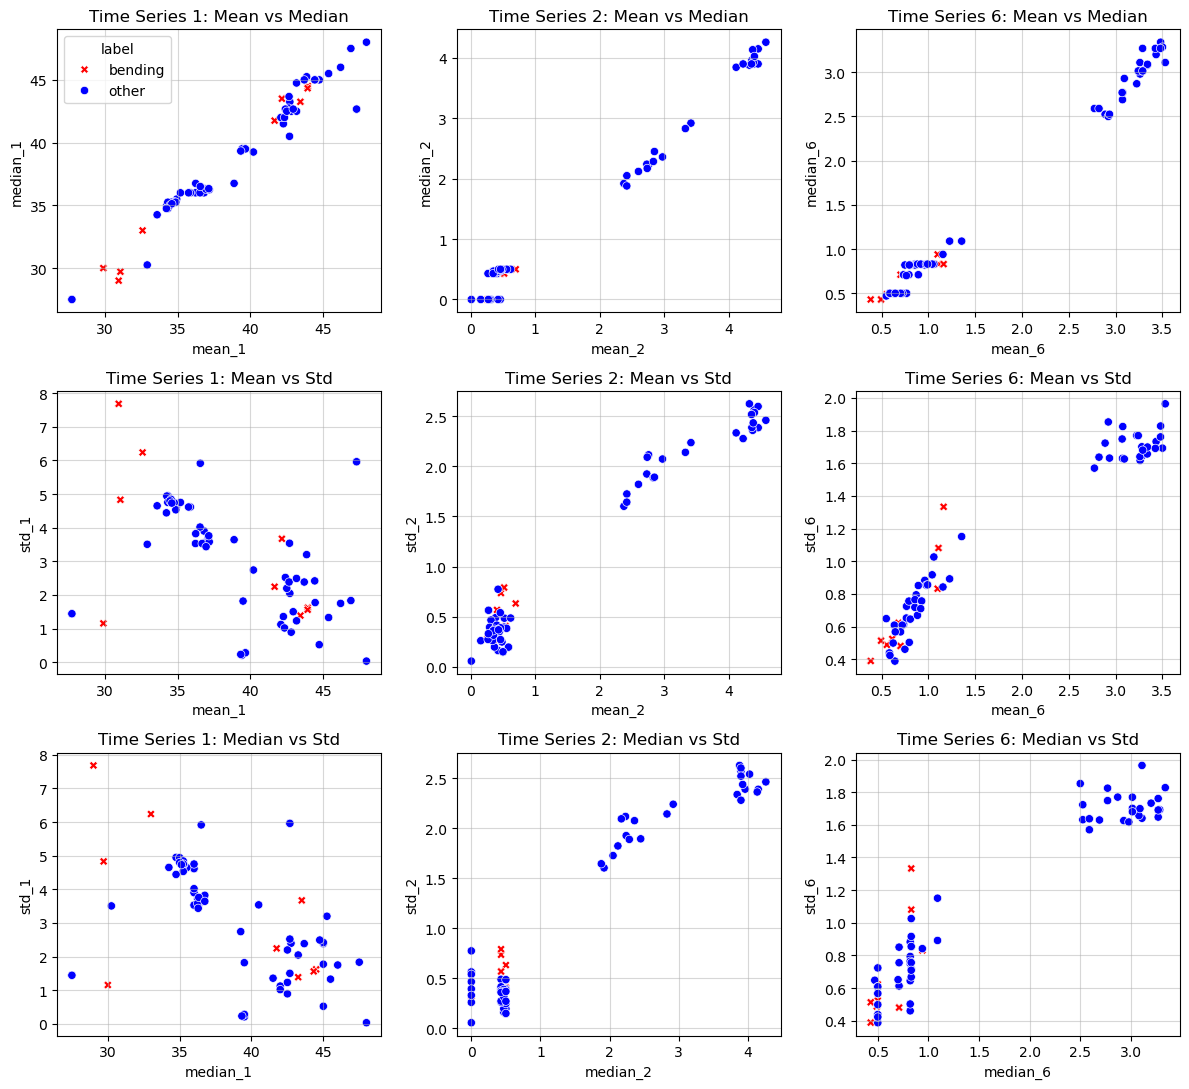

In [26]:
# Extract mean, median, and std for time series 1, 2, and 6 of training data
train_records = []
for (folder, f), df in train_data.items():
    is_bending = folder in ['bending1', 'bending2']
    row = {'label': 'bending' if is_bending else 'other'}
    for ts in [1, 2, 6]:
        col = df.iloc[:, ts - 1]
        row[f'mean_{ts}'] = col.mean()
        row[f'median_{ts}'] = col.median()
        row[f'std_{ts}'] = col.std()
    train_records.append(row)

train_df = pd.DataFrame(train_records)

# 3 feature pairs across time series 1, 2, and 6 
fig, axes = plt.subplots(3, 3, figsize=(12, 11))
pairs = [('mean', 'median'), ('mean', 'std'), ('median', 'std')]
time_series = [1, 2, 6]

for r, (fx, fy) in enumerate(pairs):
    for c, ts in enumerate(time_series):
        ax = axes[r, c]
        sns.scatterplot(
            data=train_df, x=f'{fx}_{ts}', y=f'{fy}_{ts}',
            hue='label', style='label',
            palette={'bending': 'red', 'other': 'blue'},
            markers={'bending': 'X', 'other': 'o'},
            ax=ax, legend=(r == 0 and c == 0)
        )
        ax.set_title(f'Time Series {ts}: {fx.title()} vs {fy.title()}')
        ax.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

#### ii. Splitted Plots
Break each time series in your training set into two (approximately) equal
length time series. Now instead of 6 time series for each of the training
instances, you have 12 time series for each training instance. Repeat the
experiment in 2(a)i, i.e depict scatter plots of the features extracted from both
parts of the time series 1,2, and 6. Do you see any considerable difference in
the results with those of 2(a)i?

In [27]:
# Split each time series into two equal halves (l = 2)
split_records = []
for (folder, f), df in train_data.items():
    is_bending = folder in ['bending1', 'bending2']
    row = {'label': 'bending' if is_bending else 'other'}
    
    mid = len(df) // 2
    parts = {'p1': df.iloc[:mid], 'p2': df.iloc[mid:]}
    
    for p_name, p_df in parts.items():
        for ts in [1, 2, 6]:
            col = p_df.iloc[:, ts - 1]
            row[f'mean_{ts}_{p_name}'] = col.mean()
            row[f'median_{ts}_{p_name}'] = col.median()
            row[f'std_{ts}_{p_name}'] = col.std()
            
    split_records.append(row)

split_df = pd.DataFrame(split_records)

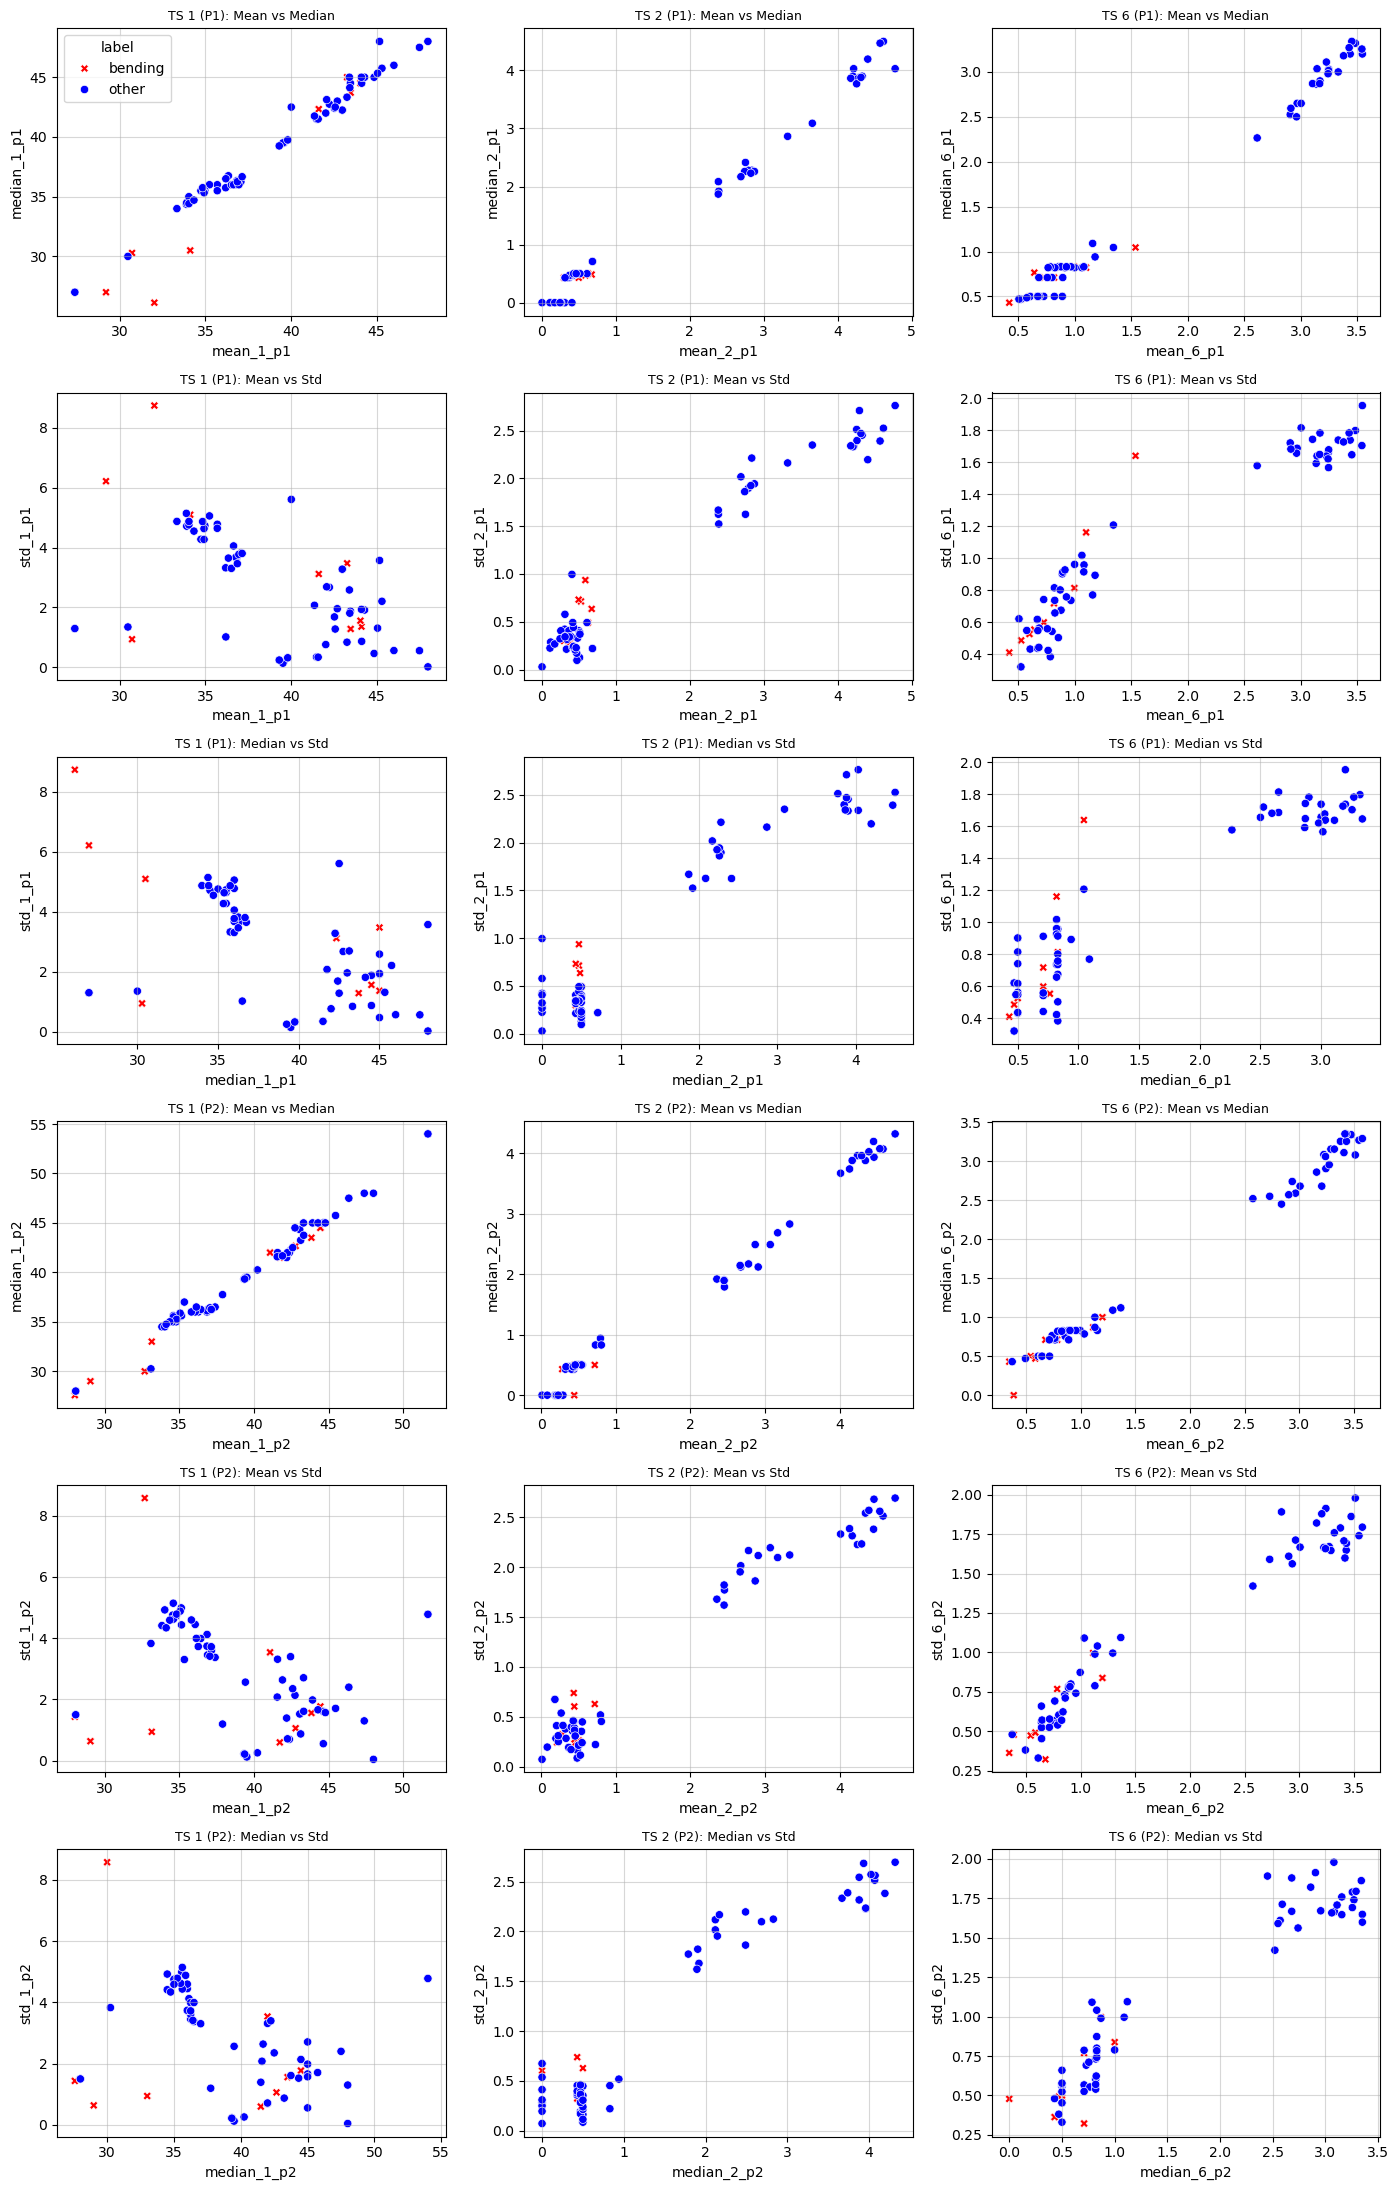

In [28]:
# Scatter Plot Grid: First half (Rows 0-2) and 2nd half(Rows 3-5)
fig, axes = plt.subplots(6, 3, figsize=(14, 22))
pairs = [('mean', 'median'), ('mean', 'std'), ('median', 'std')]
time_series = [1, 2, 6]

for part_idx, p_name in enumerate(['p1', 'p2']):
    for r, (fx, fy) in enumerate(pairs):
        row_pos = part_idx * 3 + r
        for c, ts in enumerate(time_series):
            ax = axes[row_pos, c]
            x_col = f'{fx}_{ts}_{p_name}'
            y_col = f'{fy}_{ts}_{p_name}'
            
            sns.scatterplot(
                data=split_df, x=x_col, y=y_col,
                hue='label', style='label',
                palette={'bending': 'red', 'other': 'blue'},
                markers={'bending': 'X', 'other': 'o'},
                ax=ax, legend=(row_pos == 0 and c == 0)
            )
            ax.set_title(f'TS {ts} ({p_name.upper()}): {fx.title()} vs {fy.title()}', fontsize=9)
            ax.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

Comparison with 2(a)i Results:  
There are **no significant difference** between the scatter plots of the split time series and the full time series from 2(a)i. They are very similar, almost identical.

#### iii. Time Series Segments
Break each time series in your training set into l ∈ {1, 2, . . . , 20} time series
of approximately equal length and use logistic regression
to solve the binary classification problem, using time-domain features. Remember that breaking
each of the time series does not change the number of instances. It only
changes the number of features for each instance.  
Calculate the p-values for
your logistic regression parameters in each model corresponding to each value
of l and refit a logistic regression model using your pruned set of features.6
Alternatively, you can use backward selection using sklearn.feature selection
or glm in R. Use 5-fold cross-validation to determine the best value of the pair
(l, p), where p is the number of features used in recursive feature elimination.

In [29]:
def extract_features_for_l(data_dict, l):
    x_row = []
    y_labels = []

    for (folder, filename), df in data_dict.items():
        # 1 for bending, 0 for other
        is_bending = 1 if folder in ['bending1', 'bending2'] else 0
        y_labels.append(is_bending)
        
        # Calculate ~equal segment length
        total_len = len(df)
        seg_len = total_len // l
        row_feat = {}
        
        for l_idx in range(l):
            start = l_idx * seg_len
            end = (l_idx + 1) * seg_len if l_idx < l - 1 else total_len
            df_seg = df.iloc[start:end]
            
            # Mean, median, std for each 6 time series
            for ts_idx in range(1, 7):
                series = df_seg.iloc[:, ts_idx - 1]
                row_feat[f'mean_ts{ts_idx}_l{l_idx+1}'] = series.mean()
                row_feat[f'median_ts{ts_idx}_l{l_idx+1}'] = series.median()
                row_feat[f'std_ts{ts_idx}_l{l_idx+1}'] = series.std(ddof=1) if len(series) > 1 else 0.0
                
        x_row.append(row_feat)
        
    x_df = pd.DataFrame(x_row)
    y = np.array(y_labels)
    return x_df, y

In [30]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_records = []
l_stats = []

# l ∈ {1, 2, . . . , 20} time series of approximately equal length
for l in range(1, 21):
    x_l, y_train = extract_features_for_l(train_data, l)
    total_features = x_l.shape[1]
    max_p = min(total_features, 15)
    
    p_fold_accuracies = {p: [] for p in range(1, max_p + 1)}

    # Each of the 5 cross-validation folds
    for train_idx, val_idx in skf.split(x_l, y_train):
        X_tr, X_val = x_l.iloc[train_idx].values, x_l.iloc[val_idx].values
        y_tr, y_val = y_train[train_idx], y_train[val_idx]
        
        # Standardize features with just training fold data
        scaler = StandardScaler()
        X_tr_scaled = scaler.fit_transform(X_tr)
        X_val_scaled = scaler.transform(X_val)
        
        # Logistic regression 
        base_model = LogisticRegression(C=1e5, solver='liblinear', random_state=42, max_iter=200)
        
        # Backward selection via RFE
        rfe = RFE(estimator=base_model, n_features_to_select=1, step=1)
        rfe.fit(X_tr_scaled, y_tr) # Fit logistic regression model on features
        
        # Evaluate performance across candidate p values
        for p in range(1, max_p + 1):
            mask = (rfe.ranking_ <= p)
            clf = LogisticRegression(C=1e5, solver='liblinear', random_state=42, max_iter=200)
            clf.fit(X_tr_scaled[:, mask], y_tr)
            acc = clf.score(X_val_scaled[:, mask], y_val)
            p_fold_accuracies[p].append(acc)
            
    # Track each p for specific l
    best_p = None
    best_acc = -1.0
    best_error = 1.0
    
    for p in range(1, max_p + 1):
        mean_acc = np.mean(p_fold_accuracies[p])
        cv_err = 1.0 - mean_acc
        
        cv_records.append({
            'l': l,
            'p': p,
            'mean_cv_accuracy': mean_acc,
            'cv_error': cv_err
        })
        
        # Tie-breaker: smaller error, then smaller p
        if (cv_err < best_error) or (cv_err == best_error and (best_p is None or p < best_p)):
            best_p = p
            best_acc = mean_acc
            best_error = cv_err
            
    l_stats.append({
        'Segment (l)': l,
        'Best p': best_p,
        'CV Accuracy': round(best_acc, 4),
        'CV Error': round(best_error, 4)
    })

# Per-segment best results
results_per_l_df = pd.DataFrame(l_stats)
display(results_per_l_df)

# Optimal (l*, p*)
cv_df = pd.DataFrame(cv_records)
best_config = cv_df.sort_values(by=['cv_error', 'p', 'l']).iloc[0]
best_l = int(best_config['l'])
best_p = int(best_config['p'])

optimal_df = pd.DataFrame([{
    'Optimal l': best_l,
    'Optimal p': best_p,
    'CV Accuracy': round(best_config['mean_cv_accuracy'], 4),
    'CV Error': round(best_config['cv_error'], 4)
}])

display(optimal_df)

,Segment (l),Best p,CV Accuracy,CV Error
0,1,4,0.9571,0.0429
1,2,8,0.9143,0.0857
2,3,2,0.9714,0.0286
3,4,1,0.9571,0.0429
4,5,1,0.9571,0.0429
5,6,8,0.9714,0.0286
6,7,4,0.9714,0.0286
7,8,15,0.9714,0.0286
8,9,9,0.9714,0.0286
9,10,2,0.9571,0.0429


,Optimal l,Optimal p,CV Accuracy,CV Error
0,13,4,0.9857,0.0143


Explain what the right way and the wrong way are to perform cross-validation
in this problem. Obviously, use the right way! Also, you may encounter the
problem of class imbalance, which may make some of your folds not having
any instances of the rare class. In such a case, you can use stratified cross
validation. Research what it means and use it if needed.

The wrong way to perform cross validation is by performing recursive feature elimination (RFE) on the training dataset before the cross validation, which can result in cross validation scores that does not generalize properly.   
The correct way is to perform the RFE of each cross validation split.

Stratified cross validation is used to make sure each fold has the same class proportions as the overall dataset.

#### iv. Confusion Matrix
Report the confusion matrix and show the ROC and AUC for your classifier
on train data. Report the parameters of your logistic regression βi
’s as well
as the p-values associated with them.

Selected 4 Features (l* = 13): ['mean_ts5_l2' 'median_ts5_l2' 'median_ts4_l10' 'mean_ts5_l13']

 Confusion Matrix:


,Predicted: Other (0),Predicted: Bending (1)
Actual: Other (0),60,0
Actual: Bending (1),0,9


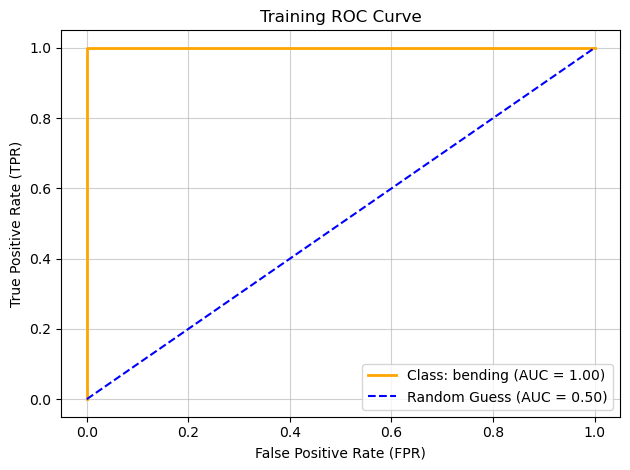

In [31]:
# From iii.
optimal_l = best_l
optimal_p = best_p

X_train_df, y_train = extract_features_for_l(train_data, l=optimal_l)

# Selected top 4 features using RFE
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_df)

base_lr = LogisticRegression(C=1e5, solver='liblinear', random_state=42, max_iter=200)
rfe_final = RFE(estimator=base_lr, n_features_to_select=optimal_p, step=1)
rfe_final.fit(X_train_scaled, y_train)

# Selected features 
selected_features = np.array(X_train_df.columns[rfe_final.support_].tolist())
print(f"Selected {optimal_p} Features (l* = {optimal_l}):", selected_features)

# Final logistic regression model on selected features
X_train_selected = X_train_scaled[:, rfe_final.support_]
final_model = LogisticRegression(C=1e5, solver='liblinear', random_state=42, max_iter=200)
final_model.fit(X_train_selected, y_train)

y_train_pred = final_model.predict(X_train_selected)
y_train_prob = final_model.predict_proba(X_train_selected)[:, 1]

# Confusion Matrix
cm = confusion_matrix(y_train, y_train_pred)
cm_df = pd.DataFrame(
    cm,
    index=['Actual: Other (0)', 'Actual: Bending (1)'],
    columns=['Predicted: Other (0)', 'Predicted: Bending (1)']
)
print("\n Confusion Matrix:")
display(cm_df)

# ROC Curve and AUC 
fpr, tpr, _ = roc_curve(y_train, y_train_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='orange', lw=2, label=f'Class: bending (AUC = {roc_auc:.2f})') # Model Curve
plt.plot([0, 1], [0, 1], color='blue', lw=1.5, linestyle='--', label='Random Guess (AUC = 0.50)') # Baseline
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Training ROC Curve')
plt.legend()
plt.grid(True, alpha=0.6)
plt.tight_layout()
plt.show()

In [32]:
# Parameters and p-values
X_train_selected_df = pd.DataFrame(X_train_selected, columns=selected_features)
X_train_new = sm.add_constant(X_train_selected_df)
logit_model_selected = sm.Logit(y_train, X_train_new)
model_selected = logit_model_selected.fit(method='lbfgs', maxiter=200, disp=False)
print("\nLogistic Regression Parameters and Associated p-values:")
print(model_selected.summary())


Logistic Regression Parameters and Associated p-values:
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       64
Method:                           MLE   Df Model:                            4
Date:                Sun, 18 Oct 2026   Pseudo R-squ.:                  0.9999
Time:                        22:05:02   Log-Likelihood:             -0.0018879
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 6.922e-11
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const            -22.4259    240.727     -0.093      0.926    -494.242     449.390
mean_ts5_l2       11.5113   1323.420      0.009      0.993   -

#### v. Test Classifier
Test the classifier on the test set. Remember to break the time series in
your test set into the same number of time series into which you broke your
training set. Remember that the classifier has to be tested using the features
extracted from the test set. Compare the accuracy on the test set with the
cross-validation accuracy you obtained previously.

Test Set Confusion Matrix:


,Predicted: Other (0),Predicted: Bending (1)
Actual: Other (0),14,1
Actual: Bending (1),0,4


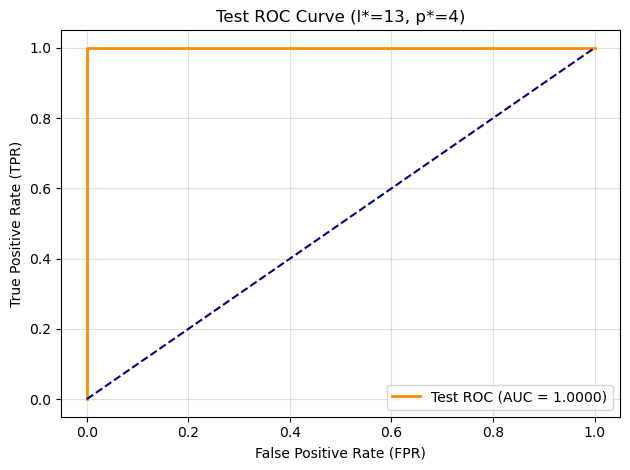

Test Accuracy: 0.9474
Cross-Validation Accuracy: 0.9857
Test AUC: 1.0000


In [33]:
# Extract features from test set
X_test_df, y_test = extract_features_for_l(test_data, l=optimal_l)

# Transform test features
X_test_scaled = scaler.transform(X_test_df)

# Same top 4 features identified by RFE
X_test_selected = X_test_scaled[:, rfe_final.support_]

# Predict probabilities and binary labels on the test set
y_test_pred = final_model.predict(X_test_selected)
y_test_prob = final_model.predict_proba(X_test_selected)[:, 1]

# Test Confusion Matrix
cm_test = confusion_matrix(y_test, y_test_pred)
cm_test_df = pd.DataFrame(
    cm_test,
    index=['Actual: Other (0)', 'Actual: Bending (1)'],
    columns=['Predicted: Other (0)', 'Predicted: Bending (1)']
)
print("Test Set Confusion Matrix:")
display(cm_test_df)

# Test ROC Curve and AUC
fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)
roc_auc_test = auc(fpr_test, tpr_test)

plt.figure()
plt.plot(fpr_test, tpr_test, color='darkorange', lw=2, label=f'Test ROC (AUC = {roc_auc_test:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title(f'Test ROC Curve (l*={optimal_l}, p*={optimal_p})')
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()
cv_result_row = optimal_df.iloc[0]
print(f"Test Accuracy: {final_model.score(X_test_selected, y_test):.4f}")
print(f"Cross-Validation Accuracy: {cv_result_row['CV Accuracy']:.4f}")
print(f"Test AUC: {roc_auc_test:.4f}")

The test accuracy is very close to my cross-validation and training scores.

#### vi. Separation
Do your classes seem to be well-separated to cause instability in calculating
logistic regression parameters?

Yes, the classes seem to be very well-separated, as reflected from the paramters, p-values, and the high training accuracy and training AUC. Thus, that may mean the classes is causing the instability in calculating the regression parameters.

#### vii. Imbalance
From the confusion matrices you obtained, do you see imbalanced classes?
If yes, build a logistic regression model based on case-control sampling and
adjust its parameters. Report the confusion matrix, ROC, and AUC of the
model.

Yes, from the confusion matrices, there is significantly a higher number for class 0 'other' than class 1 'bending'.

Intercept correction: -1.8971
Adjusted intercept: -10.8496
Case-Control Model Test Confusion Matrix:


,Predicted: Other (0),Predicted: Bending (1)
Actual: Other (0),14,1
Actual: Bending (1),0,4


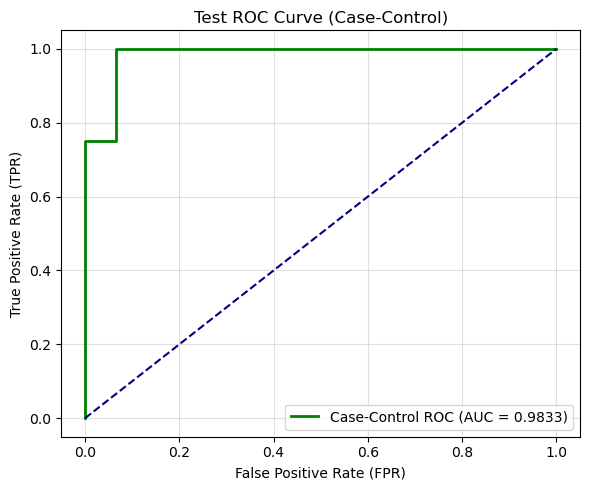

Case-Control Test AUC: 0.9833


In [34]:
# Case-control sampling: keep bending cases and sample an equal number of controls
rng = np.random.default_rng(42)
case_idx = np.flatnonzero(y_train == 1)
control_idx = rng.choice(np.flatnonzero(y_train == 0), size=len(case_idx), replace=False)
sampled_idx = np.r_[case_idx, control_idx]

model_controlled = LogisticRegression(C=1e5, solver='liblinear', random_state=42, max_iter=200)

model_controlled.fit(X_train_selected[sampled_idx], y_train[sampled_idx])

# Correct the intercept: logit(original prior) - logit(sampled prior)
pi = y_train.mean()
pi_sample = y_train[sampled_idx].mean()
intercept_correction = np.log(pi / (1 - pi)) - np.log(pi_sample / (1 - pi_sample))
model_controlled.intercept_ += intercept_correction
print(f"Intercept correction: {intercept_correction:.4f}")
print(f"Adjusted intercept: {model_controlled.intercept_[0]:.4f}")

# Predict on test data
y_test_pred_bal = model_controlled.predict(X_test_selected)
y_test_prob_bal = model_controlled.predict_proba(X_test_selected)[:, 1]

# Confusion Matrix
cm_controlled = confusion_matrix(y_test, y_test_pred_bal)
cm_controlled_df = pd.DataFrame(
    cm_controlled,
    index=['Actual: Other (0)', 'Actual: Bending (1)'],
    columns=['Predicted: Other (0)', 'Predicted: Bending (1)']
)
print("Case-Control Model Test Confusion Matrix:")
display(cm_controlled_df)

# ROC Curve and AUC
fpr_bal, tpr_bal, _ = roc_curve(y_test, y_test_prob_bal)
roc_auc_bal = auc(fpr_bal, tpr_bal)

plt.figure(figsize=(6, 5))
plt.plot(fpr_bal, tpr_bal, color='green', lw=2, label=f'Case-Control ROC (AUC = {roc_auc_bal:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Test ROC Curve (Case-Control)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()
print(f"Case-Control Test AUC: {roc_auc_bal:.4f}")

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments
Repeat 2(a)iii using L1-penalized logistic regression,8
i.e. instead of using pvalues for variable selection, use L1 regularization. Note that in this problem,
you have to cross-validate for both l, the number of time series into which you
break each of your instances, and λ, the weight of L1 penalty in your logistic
regression objective function (or C, the budget). Packages usually perform
cross-validation for λ automatically.9

In [35]:
C_grid = np.logspace(-3, 3, 7) # Regularization budget grid

l1_cv_records = []
l1_stats = []

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

best_l_l1 = None
best_C_l1 = None
best_score_l1 = -1.0
best_error_l1 = 1.0

# l ∈ {1, 2, . . . , 20} 
for l in range(1, 21):
    X_l, y_train = extract_features_for_l(train_data, l)
    
    best_p = None
    best_acc = -1.0
    best_err = 1.0
    
    for C_val in C_grid:
        fold_accs = []
        for train_idx, val_idx in skf.split(X_l, y_train):
            X_tr, X_val = X_l.iloc[train_idx].values, X_l.iloc[val_idx].values
            y_tr, y_val = y_train[train_idx], y_train[val_idx]
            
            # Standardize features
            scaler = StandardScaler()
            X_tr_scaled = scaler.fit_transform(X_tr)
            X_val_scaled = scaler.transform(X_val)
            
            # Fit L1 penalized logistic regression
            l1_model = LogisticRegression(penalty='l1', solver='liblinear', C=C_val, random_state=42, max_iter=300)
            l1_model.fit(X_tr_scaled, y_tr)
            
            acc = l1_model.score(X_val_scaled, y_val)
            fold_accs.append(acc)
            
        mean_acc = np.mean(fold_accs)
        cv_err = 1.0 - mean_acc
        
        l1_cv_records.append({
            'l': l,
            'C': C_val,
            'mean_cv_accuracy': mean_acc,
            'cv_error': cv_err
        })
        
        # Track best C for this specific l
        if (cv_err < best_err) or (cv_err == best_err and (best_p is None or C_val > best_p)):
            best_err = cv_err
            best_acc = mean_acc
            best_p = C_val

    l1_stats.append({
        'Segment (l)': l,
        'Best C': best_p,
        'CV Accuracy': round(best_acc, 4),
        'CV Error': round(best_err, 4)
    })
    
    # Best (l, C)
    if (best_err < best_error_l1) or (best_err == best_error_l1 and (best_l_l1 is None or l < best_l_l1)):
        best_error_l1 = best_err
        best_score_l1 = best_acc
        best_l_l1 = l
        best_C_l1 = best_p

# Per-segment best results
results_per_l_l1_df = pd.DataFrame(l1_stats)
display(results_per_l_l1_df)

optimal_l1_df = pd.DataFrame([{
    'Optimal l': best_l_l1,
    'Optimal C': best_C_l1,
    'CV Accuracy': round(best_score_l1, 4),
    'CV Error': round(best_error_l1, 4)
}])
display(optimal_l1_df)

,Segment (l),Best C,CV Accuracy,CV Error
0,1,1000.0,0.9571,0.0429
1,2,10.0,0.9286,0.0714
2,3,1.0,0.9714,0.0286
3,4,1.0,0.9714,0.0286
4,5,1.0,0.9571,0.0429
5,6,1.0,0.9714,0.0286
6,7,1.0,0.9429,0.0571
7,8,1000.0,0.9714,0.0286
8,9,1.0,0.9571,0.0429
9,10,100.0,0.9857,0.0143


,Optimal l,Optimal C,CV Accuracy,CV Error
0,10,100.0,0.9857,0.0143


In [36]:
# Fit the selected L1 model on all training data and evaluate on the test set
X_train_l1, y_train_l1 = extract_features_for_l(train_data, best_l_l1)
X_test_l1, y_test_l1 = extract_features_for_l(test_data, best_l_l1)
scaler_l1 = StandardScaler()
X_train_l1_scaled = scaler_l1.fit_transform(X_train_l1)
X_test_l1_scaled = scaler_l1.transform(X_test_l1)

final_l1 = LogisticRegression(penalty='l1', solver='liblinear', C=best_C_l1,
                              random_state=42, max_iter=300)
final_l1.fit(X_train_l1_scaled, y_train_l1)
print(f"L1 Test Accuracy: {final_l1.score(X_test_l1_scaled, y_test_l1):.4f}")
print(f"L1 Cross-Validation Accuracy: {best_score_l1:.4f}")
print(f"RFE Test Accuracy: {final_model.score(X_test_selected, y_test):.4f}")

L1 Test Accuracy: 0.9474
L1 Cross-Validation Accuracy: 0.9857
RFE Test Accuracy: 0.9474


#### ii. Comparison
Compare the L1-penalized with variable selection using p-values. Which one
performs better? Which one is easier to implement?

They both perform the same when it comes to accuracy on the test data. However, L1-regularization is easier to implement as feature selection is handled automatically.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments
Find the best l in the same way as you found it in 2(b)i to build an L1-
penalized multinomial regression model to classify all activities in your training set.10 Report your test error. Research how confusion matrices and ROC
curves are defined for multiclass classification and show them for this problem
if possible.

In [37]:
activity_folders = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
folder_to_label = {folder: idx for idx, folder in enumerate(activity_folders)}

def extract_multiclass_features(data_dict, l):
    x_rows = []
    y_labels = []
    for (folder, filename), df in data_dict.items():
        y_labels.append(folder_to_label[folder])
        total_len = len(df)
        seg_len = total_len // l
        row_feat = {}
        for l_idx in range(l):
            start = l_idx * seg_len
            end = (l_idx + 1) * seg_len if l_idx < l - 1 else total_len
            df_seg = df.iloc[start:end]
            for ts_idx in range(1, 7):
                series = df_seg.iloc[:, ts_idx - 1]
                row_feat[f'mean_ts{ts_idx}_l{l_idx+1}'] = series.mean()
                row_feat[f'median_ts{ts_idx}_l{l_idx+1}'] = series.median()
                row_feat[f'std_ts{ts_idx}_l{l_idx+1}'] = series.std(ddof=1) if len(series) > 1 else 0.0
        x_rows.append(row_feat)
    return pd.DataFrame(x_rows), np.array(y_labels)

In [38]:
l_multiclass_stats = []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

best_l_multi = None
best_C_multi = None
best_acc_multi = -1.0
best_err_multi = 1.0

# 5-Fold Stratified Cross-Validation across l in {1, ..., 20}
for l in range(1, 21):
    X_l, y_train_multi = extract_multiclass_features(train_data, l)
    best_C_for_l = None
    best_acc_for_l = -1.0

    for C_val in C_grid:
        fold_accs = []
        for train_idx, val_idx in skf.split(X_l, y_train_multi):
            X_tr, X_val = X_l.iloc[train_idx].values, X_l.iloc[val_idx].values
            y_tr, y_val = y_train_multi[train_idx], y_train_multi[val_idx]

            scaler = StandardScaler()
            X_tr_scaled = scaler.fit_transform(X_tr)
            X_val_scaled = scaler.transform(X_val)

            multi_model = LogisticRegression(
                penalty='l1',
                solver='saga',
                C=C_val,
                random_state=42,
                max_iter=20000,
                tol=1e-3
            )
            multi_model.fit(X_tr_scaled, y_tr)
            fold_accs.append(multi_model.score(X_val_scaled, y_val))

        mean_acc = np.mean(fold_accs)
        if mean_acc > best_acc_for_l:
            best_acc_for_l = mean_acc
            best_C_for_l = C_val

    cv_err = 1.0 - best_acc_for_l
    l_multiclass_stats.append({
        'Segment (l)': l,
        'Best C': best_C_for_l,
        'CV Accuracy': round(best_acc_for_l, 4),
        'CV Error': round(cv_err, 4)
    })

    if (cv_err < best_err_multi) or (cv_err == best_err_multi and (best_l_multi is None or l < best_l_multi)):
        best_err_multi = cv_err
        best_acc_multi = best_acc_for_l
        best_l_multi = l
        best_C_multi = best_C_for_l

# Per-segment 
results_per_l_multi_df = pd.DataFrame(l_multiclass_stats)
print("Cross-Validation Results per l:")
display(results_per_l_multi_df)

optimal_multi_df = pd.DataFrame([{
    'Optimal l': best_l_multi,
    'Optimal C': best_C_multi,
    'CV Accuracy': round(best_acc_multi, 4),
    'CV Error': round(best_err_multi, 4)
}])
print("\nOptimal Multiclass Configuration:")
display(optimal_multi_df)

# Trai model on full training set with optimal l*
X_train_m, y_train_m = extract_multiclass_features(train_data, best_l_multi)
scaler_m = StandardScaler()
X_train_m_scaled = scaler_m.fit_transform(X_train_m)

final_multi = LogisticRegression(
    penalty='l1',
    solver='saga',
    C=best_C_multi,
    random_state=42,
    max_iter=20000,
    tol=1e-3
)
final_multi.fit(X_train_m_scaled, y_train_m)

# Predict on Test Set
X_test_m, y_test_m = extract_multiclass_features(test_data, best_l_multi)
X_test_m_scaled = scaler_m.transform(X_test_m)

y_test_pred_m = final_multi.predict(X_test_m_scaled)
y_test_prob_m = final_multi.predict_proba(X_test_m_scaled)

test_acc_m = final_multi.score(X_test_m_scaled, y_test_m)
test_err_m = 1.0 - test_acc_m

print(f"Test Accuracy: {test_acc_m:.4f}")
print(f"Test Error: {test_err_m:.4f}")

Cross-Validation Results per l:


,Segment (l),Best C,CV Accuracy,CV Error
0,1,10.0,0.9121,0.0879
1,2,100.0,0.8703,0.1297
2,3,100.0,0.8418,0.1582
3,4,100.0,0.8418,0.1582
4,5,10.0,0.8703,0.1297
5,6,10.0,0.8275,0.1725
6,7,100.0,0.8132,0.1868
7,8,100.0,0.8275,0.1725
8,9,10.0,0.8121,0.1879
9,10,100.0,0.8275,0.1725



Optimal Multiclass Configuration:


,Optimal l,Optimal C,CV Accuracy,CV Error
0,1,10.0,0.9121,0.0879


Test Accuracy: 0.9474
Test Error: 0.0526


In multi-class classification, the confusion matrix accounts for the multiple classes as a NxN matrix where N is the number of classes. Each cell in the matrix represents how often a specific actual class (row) was predicted as another class (column). 

For multiclass ROC and AUC, there is a One-vs-Rest and One-vs-One approach. One-vs-Rest treats each individual class as the positive class and combining all other classes as the negative class. One-vs-One fits one binary classifier per class pair and can take longer time than One-vs-Rest.


Multiclass Test Confusion Matrix:


,Pred: bending1,Pred: bending2,Pred: cycling,Pred: lying,Pred: sitting,Pred: standing,Pred: walking
Actual: bending1,2,0,0,0,0,0,0
Actual: bending2,0,2,0,0,0,0,0
Actual: cycling,0,0,3,0,0,0,0
Actual: lying,0,0,0,3,0,0,0
Actual: sitting,0,0,0,0,2,1,0
Actual: standing,0,0,0,0,0,3,0
Actual: walking,0,0,0,0,0,0,3


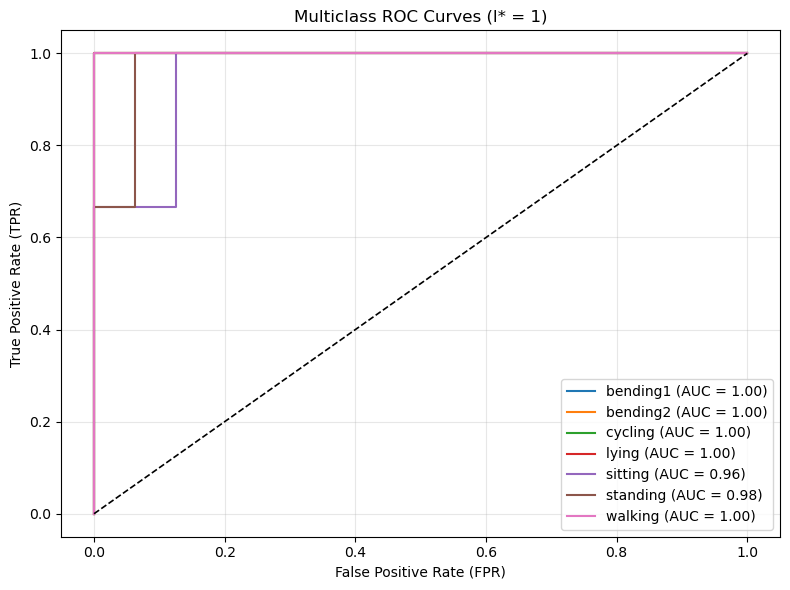

In [39]:
# Multiclass Confusion Matrix
cm_multiclass = confusion_matrix(y_test_m, y_test_pred_m)
cm_multiclass_df = pd.DataFrame(
    cm_multiclass,
    index=[f'Actual: {c}' for c in activity_folders],
    columns=[f'Pred: {c}' for c in activity_folders]
)
print("\nMulticlass Test Confusion Matrix:")
display(cm_multiclass_df)

# One-vs-Rest Multiclass ROC & AUC Curves
y_test_bin = label_binarize(y_test_m, classes=list(range(len(activity_folders))))
plt.figure(figsize=(8, 6))

for i, class_name in enumerate(activity_folders):
    fpr_i, tpr_i, _ = roc_curve(y_test_bin[:, i], y_test_prob_m[:, i])
    auc_i = auc(fpr_i, tpr_i)
    plt.plot(fpr_i, tpr_i, lw=1.5, label=f'{class_name} (AUC = {auc_i:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.2)
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title(f'Multiclass ROC Curves (l* = {best_l_multi})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### ii. Naive Bayes
Repeat 2(c)i using a Na¨ıve Bayes’ classifier. Use both Gaussian and Multinomial priors and compare the results.

In [40]:
# Cross-Validation for Gaussian Naive Bayes l*
best_l_gnb = None
best_acc_gnb_cv = -1.0
gnb_stats = []

for l in range(1, 21):
    X_l, y_tr_m = extract_multiclass_features(train_data, l)
    fold_scores = []
    for train_idx, val_idx in skf.split(X_l, y_tr_m):
        X_tr, X_val = X_l.iloc[train_idx].values, X_l.iloc[val_idx].values
        y_tr, y_val = y_tr_m[train_idx], y_tr_m[val_idx]
        
        clf_gnb = GaussianNB()
        clf_gnb.fit(X_tr, y_tr)
        fold_scores.append(clf_gnb.score(X_val, y_val))
        
    mean_score = np.mean(fold_scores)
    gnb_stats.append({'Segment (l)': l, 'CV Accuracy': round(mean_score, 4), 'CV Error': round(1.0 - mean_score, 4)})
    if mean_score > best_acc_gnb_cv:
        best_acc_gnb_cv = mean_score
        best_l_gnb = l

print(f"Gaussian NB Optimal l*: {best_l_gnb} (CV Accuracy = {best_acc_gnb_cv:.4f})")

# Cross-Validation for Multinomial Naive Bayes l*
best_l_mnb = None
best_acc_mnb_cv = -1.0
mnb_stats = []

for l in range(1, 21):
    X_l, y_tr_m = extract_multiclass_features(train_data, l)
    fold_scores = []
    for train_idx, val_idx in skf.split(X_l, y_tr_m):
        X_tr, X_val = X_l.iloc[train_idx].values, X_l.iloc[val_idx].values
        y_tr, y_val = y_tr_m[train_idx], y_tr_m[val_idx]
        
        # MultinomialNB requires nonnegative values
        mm_scaler = MaxAbsScaler()
        X_tr_scaled = mm_scaler.fit_transform(X_tr)
        X_val_scaled = mm_scaler.transform(X_val)
        
        clf_mnb = MultinomialNB()
        clf_mnb.fit(X_tr_scaled, y_tr)
        fold_scores.append(clf_mnb.score(X_val_scaled, y_val))
        
    mean_score = np.mean(fold_scores)
    mnb_stats.append({'Segment (l)': l, 'CV Accuracy': round(mean_score, 4), 'CV Error': round(1.0 - mean_score, 4)})
    if mean_score > best_acc_mnb_cv:
        best_acc_mnb_cv = mean_score
        best_l_mnb = l

print(f"Multinomial NB Optimal l*: {best_l_mnb} (CV Accuracy = {best_acc_mnb_cv:.4f})")

Gaussian NB Optimal l*: 1 (CV Accuracy = 0.8560)
Multinomial NB Optimal l*: 4 (CV Accuracy = 0.7538)


In [41]:
# Gaussian NB test data
X_train_gnb, y_train_gnb = extract_multiclass_features(train_data, best_l_gnb)
X_test_gnb, y_test_gnb = extract_multiclass_features(test_data, best_l_gnb)

final_gnb = GaussianNB()
final_gnb.fit(X_train_gnb, y_train_gnb)
y_pred_gnb = final_gnb.predict(X_test_gnb)
y_prob_gnb = final_gnb.predict_proba(X_test_gnb)
test_acc_gnb = final_gnb.score(X_test_gnb, y_test_gnb)
test_err_gnb = 1.0 - test_acc_gnb

# Multinomial NB test data
X_train_mnb, y_train_mnb = extract_multiclass_features(train_data, best_l_mnb)
X_test_mnb, y_test_mnb = extract_multiclass_features(test_data, best_l_mnb)

mm_scaler_final = MaxAbsScaler()
X_tr_mnb_sc = mm_scaler_final.fit_transform(X_train_mnb)
X_te_mnb_sc = mm_scaler_final.transform(X_test_mnb)

final_mnb = MultinomialNB()
final_mnb.fit(X_tr_mnb_sc, y_train_mnb)
y_pred_mnb = final_mnb.predict(X_te_mnb_sc)
y_prob_mnb = final_mnb.predict_proba(X_te_mnb_sc)
test_acc_mnb = final_mnb.score(X_te_mnb_sc, y_test_mnb)
test_err_mnb = 1.0 - test_acc_mnb


Gaussian NB Test Confusion Matrix:


,Pred: bending1,Pred: bending2,Pred: cycling,Pred: lying,Pred: sitting,Pred: standing,Pred: walking
Actual: bending1,2,0,0,0,0,0,0
Actual: bending2,0,1,0,0,1,0,0
Actual: cycling,0,0,3,0,0,0,0
Actual: lying,0,0,0,3,0,0,0
Actual: sitting,0,0,0,0,3,0,0
Actual: standing,0,0,0,0,2,1,0
Actual: walking,0,0,0,0,0,0,3



Multinomial NB Test Confusion Matrix:


,Pred: bending1,Pred: bending2,Pred: cycling,Pred: lying,Pred: sitting,Pred: standing,Pred: walking
Actual: bending1,2,0,0,0,0,0,0
Actual: bending2,1,0,0,0,1,0,0
Actual: cycling,0,0,3,0,0,0,0
Actual: lying,0,0,0,3,0,0,0
Actual: sitting,0,0,0,0,2,1,0
Actual: standing,0,0,0,0,1,2,0
Actual: walking,0,0,0,0,0,0,3


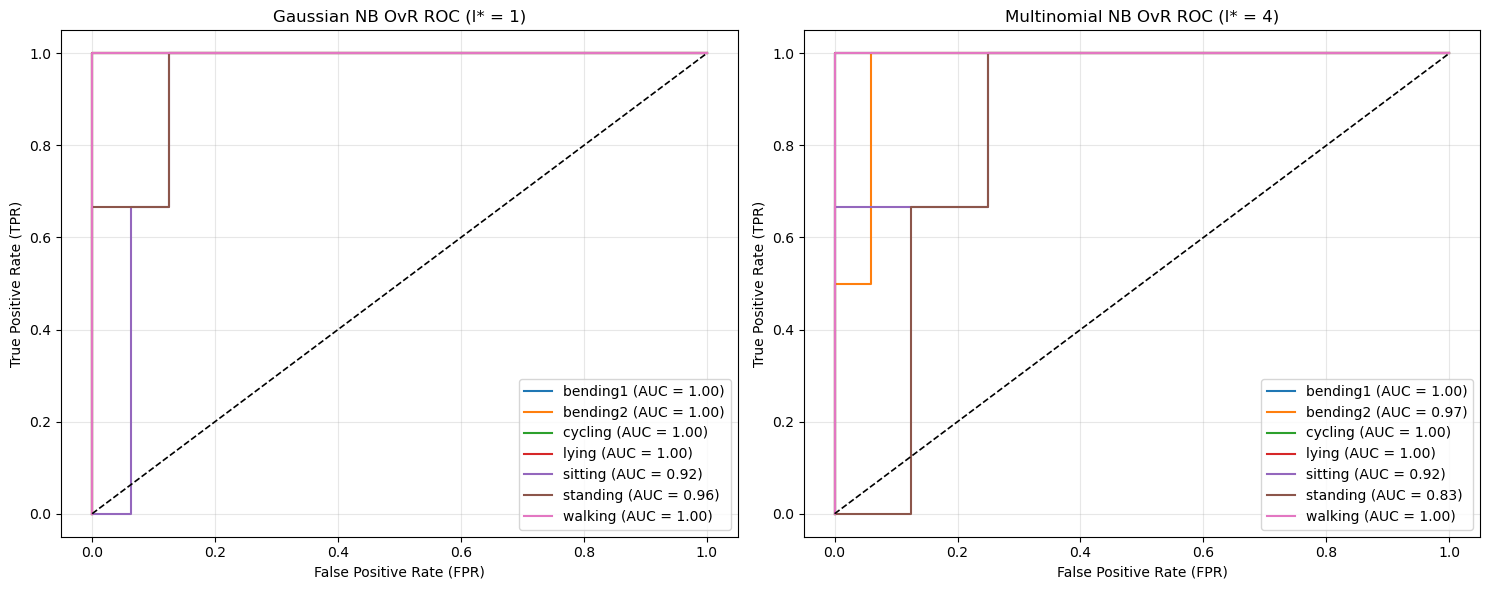

Model Comparisons:


,Model,Optimal l*,Test Accuracy,Test Error
0,Multinomial Logistic Regression (L1),1,0.9474,0.0526
1,Gaussian Naive Bayes,1,0.8421,0.1579
2,Multinomial Naive Bayes,4,0.7895,0.2105


In [42]:
# Confusion Matrices
cm_gnb_df = pd.DataFrame(
    confusion_matrix(y_test_gnb, y_pred_gnb),
    index=[f'Actual: {c}' for c in activity_folders],
    columns=[f'Pred: {c}' for c in activity_folders]
)
print("\nGaussian NB Test Confusion Matrix:")
display(cm_gnb_df)

cm_mnb_df = pd.DataFrame(
    confusion_matrix(y_test_mnb, y_pred_mnb),
    index=[f'Actual: {c}' for c in activity_folders],
    columns=[f'Pred: {c}' for c in activity_folders]
)
print("\nMultinomial NB Test Confusion Matrix:")
display(cm_mnb_df)

# ROC & AUC Curves
y_test_bin_gnb = label_binarize(y_test_gnb, classes=list(range(len(activity_folders))))
y_test_bin_mnb = label_binarize(y_test_mnb, classes=list(range(len(activity_folders))))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Gaussian NB ROC Plot
for i, class_name in enumerate(activity_folders):
    fpr_i, tpr_i, _ = roc_curve(y_test_bin_gnb[:, i], y_prob_gnb[:, i])
    auc_i = auc(fpr_i, tpr_i)
    ax1.plot(fpr_i, tpr_i, lw=1.5, label=f'{class_name} (AUC = {auc_i:.2f})')
ax1.plot([0, 1], [0, 1], 'k--', lw=1.2)
ax1.set_xlabel('False Positive Rate (FPR)')
ax1.set_ylabel('True Positive Rate (TPR)')
ax1.set_title(f'Gaussian NB OvR ROC (l* = {best_l_gnb})')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Multinomial NB ROC Plot
for i, class_name in enumerate(activity_folders):
    fpr_i, tpr_i, _ = roc_curve(y_test_bin_mnb[:, i], y_prob_mnb[:, i])
    auc_i = auc(fpr_i, tpr_i)
    ax2.plot(fpr_i, tpr_i, lw=1.5, label=f'{class_name} (AUC = {auc_i:.2f})')
ax2.plot([0, 1], [0, 1], 'k--', lw=1.2)
ax2.set_xlabel('False Positive Rate (FPR)')
ax2.set_ylabel('True Positive Rate (TPR)')
ax2.set_title(f'Multinomial NB OvR ROC (l* = {best_l_mnb})')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Comparison Summary Table
summary_table = pd.DataFrame([
    {
        'Model': 'Multinomial Logistic Regression (L1)',
        'Optimal l*': best_l_multi,
        'Test Accuracy': round(test_acc_m, 4),
        'Test Error': round(test_err_m, 4)
    },
    {
        'Model': 'Gaussian Naive Bayes',
        'Optimal l*': best_l_gnb,
        'Test Accuracy': round(test_acc_gnb, 4),
        'Test Error': round(test_err_gnb, 4)
    },
    {
        'Model': 'Multinomial Naive Bayes',
        'Optimal l*': best_l_mnb,
        'Test Accuracy': round(test_acc_mnb, 4),
        'Test Error': round(test_err_mnb, 4)
    }
])
print("Model Comparisons:")
display(summary_table)

#### iii. Comparison
Which method is better for multi-class classification in this problem?

In terms of test accuracy, multinomial logistic regression performed the best, making logistic regression better for multi-classification in this problem.

## 3. ISLR 4.8.3
This problem relates to the QDA model, in which the observations
within each class are drawn from a normal distribution with a classspecific mean vector and a class specific covariance matrix. We consider the simple case where p =1; i.e. there is only one feature.
Suppose that we have K classes, and that if an observation belongs
to the kth class then X comes from a one-dimensional normal distribution, X ∼ N(µk, σ2
k). Recall that the density function for the
one-dimensional normal distribution is given in (4.16). Prove that in
this case, the Bayes classifier is not linear. Argue that it is in fact
quadratic.
Hint: For this problem, you should follow the arguments laid out in
Section 4.4.1, but without making the assumption that σ2
1 = ... = σ2
K.


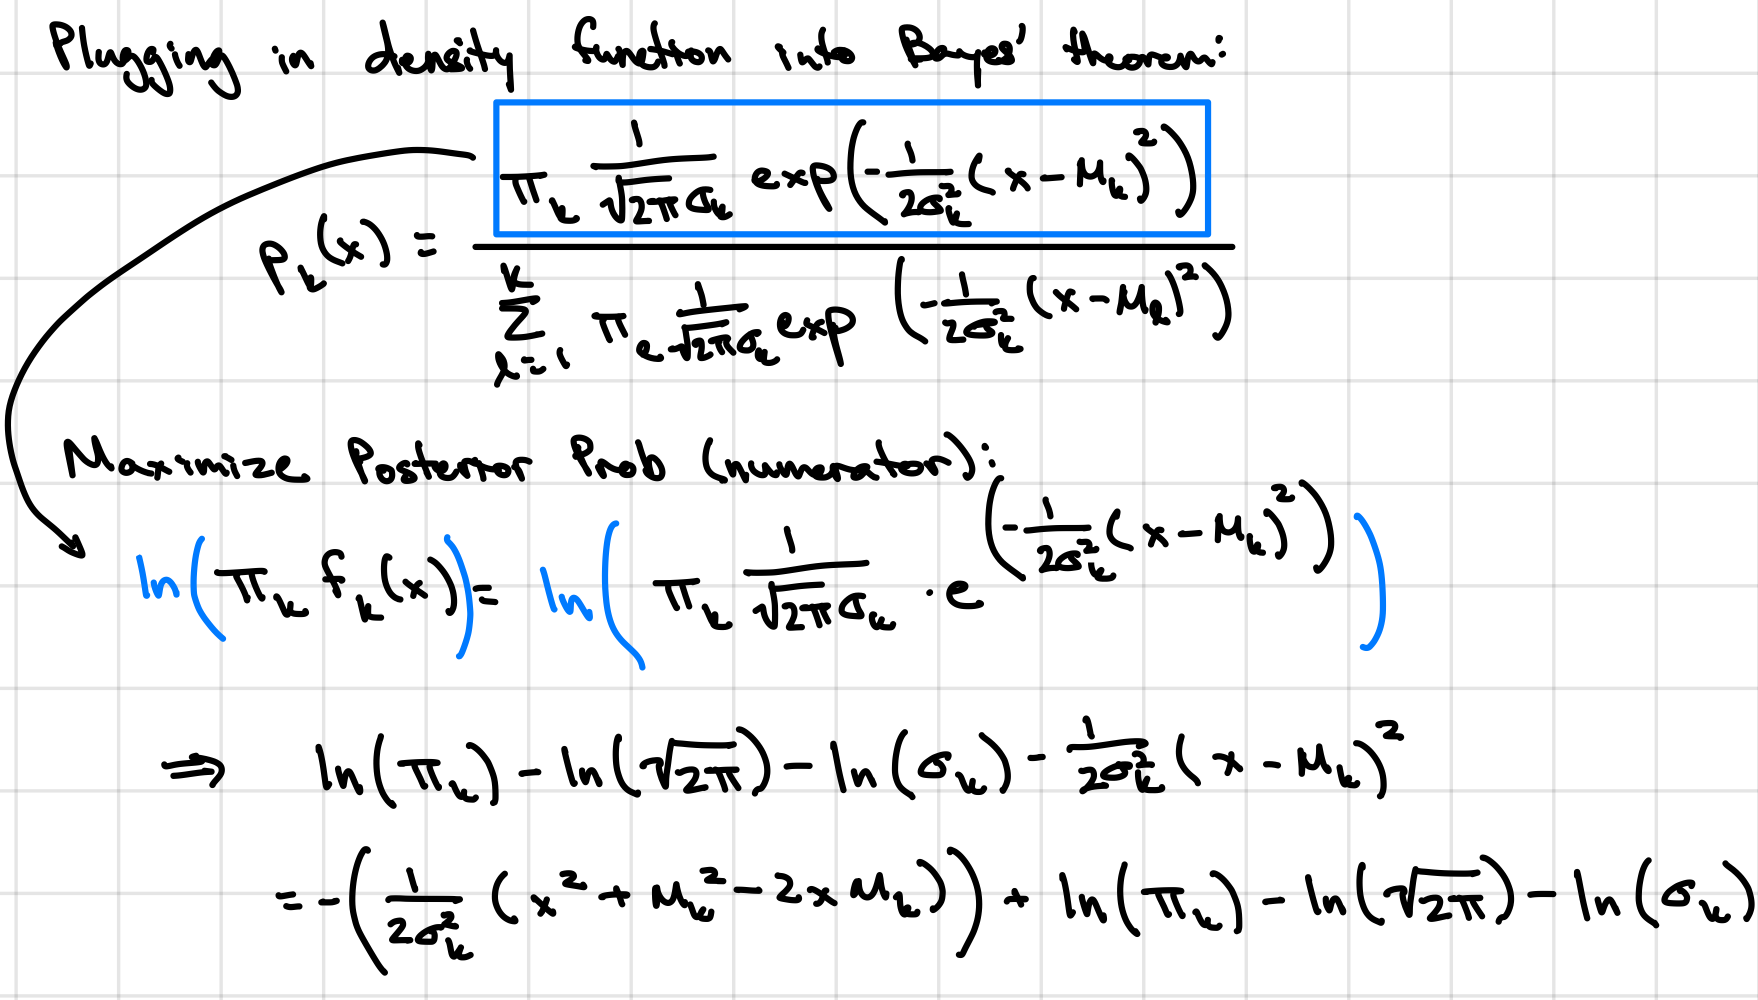

Since the first term has a quadratic function of x, this shows that Bayes classifier is not linear.

## 4. ISLR 4.8.7
Suppose that we wish to predict whether a given stock will issue a
dividend this year (“Yes” or “No”) based on X, last year’s percent
profit. We examine a large number of companies and discover that the
mean value of X for companies that issued a dividend was X¯ = 10,
while the mean for those that didn’t was X¯ =0. In addition, the
variance of X for these two sets of companies was σˆ2 = 36. Finally,
80 % of companies issued dividends. Assuming that X follows a normal distribution, predict the probability that a company will issue
a dividend this year given that its percentage profit was X =4 last
year.
Hint: Recall that the density function for a normal random variable
is f(x)= √
1
2πσ2 e−(x−µ)2/2σ2
. You will need to use Bayes’ theorem.

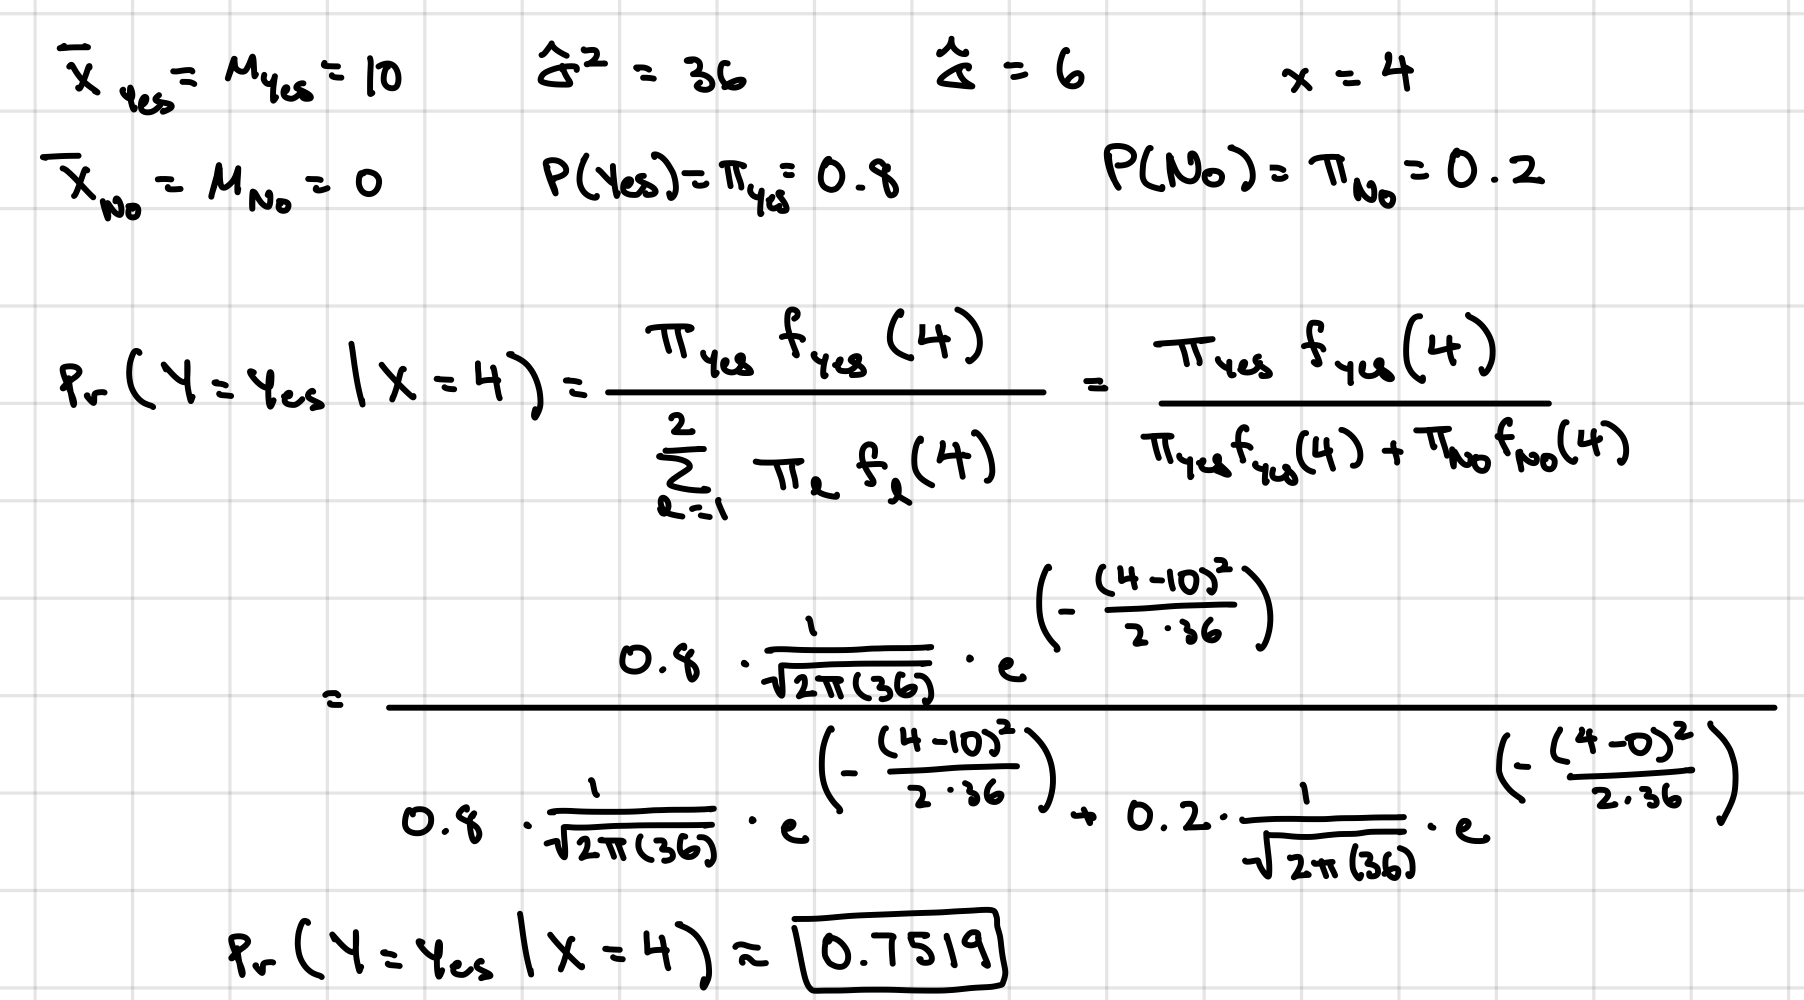